In [1]:
import sys

print(sys.executable)

E:\python_project\Geo\Sample4Geo\Geo761\Scripts\python.exe


In [3]:
%pip install -r requirements.txt

  Using cached timm-1.0.30-py3-none-any.whl.metadata (33 kB)
  Using cached albumentations-2.0.8-py3-none-any.whl.metadata (43 kB)
  Using cached transformers-5.19.0-py3-none-any.whl.metadata (32 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached setuptools-84.0.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached safetensors-0.8.0-cp310-abi3-win_amd64.whl.metadata (4.2 kB)
  Using cached albucore-0.0.24-py3-none-any.whl.metadata (5.3 kB)
  Using cached opencv_python_headless-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
  Using cached stringzilla-5.2.0-cp312-cp312-win_amd64.whl.metadata (57 kB)
  Using cached simsimd-6.5.16-cp312-cp312-win_amd64.whl.metadata (71 kB)
  Using cached tokenizers-0.23.3-cp310-abi3-win_amd64.whl.metadata (10 kB)
  Using cached hf_xet-1.7.0-cp38-abi3-win_amd64.whl.metadata (4.9 kB)
  Using cached httpx2-2.13.1-py3-none-any.whl.metadata (9.8 kB)
  Using cached httpco

In [4]:
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: E:\python_project\Geo\Sample4Geo\Geo761\Scripts\python.exe
PyTorch: 2.14.1+cpu
CUDA available: False


In [11]:
%pwd
%ls

 Volume in drive E is New Volume
 Volume Serial Number is 1849-3D50

 Directory of E:\python_project\Geo\Sample4Geo

12/10/2026  09:03 pm    <DIR>          .
12/10/2026  06:35 pm    <DIR>          ..
12/10/2026  06:35 pm             3,271 .gitignore
12/10/2026  06:35 pm             1,642 calc_distance_cvact.py
12/10/2026  06:35 pm             1,632 calc_distance_cvusa.py
12/10/2026  06:35 pm             3,192 calc_distance_vigor.py
12/10/2026  06:35 pm             7,846 eval_cvact.py
12/10/2026  06:35 pm             5,788 eval_cvusa.py
12/10/2026  06:35 pm             5,938 eval_university.py
12/10/2026  06:35 pm             6,139 eval_vigor_cross.py
12/10/2026  06:35 pm             6,123 eval_vigor_same.py
12/10/2026  08:26 pm    <DIR>          Geo761
12/10/2026  06:35 pm    <DIR>          images
26/09/2023  08:35 pm     1,626,048,556 pretrained.zip
12/10/2026  06:35 pm             2,614 README.md
12/10/2026  06:35 pm               123 requirements.txt
12/10/2026  06:35 pm    <DIR>   

### Downloading CVUSA model checkpoint

In [9]:
#pip install gdown
!gdown "1dZ9itDjS-h5KHc23OQb8oHqJ3KoSaPyS"

Downloading...
From (original): https://drive.google.com/uc?id=1dZ9itDjS-h5KHc23OQb8oHqJ3KoSaPyS
From (redirected): https://drive.google.com/uc?id=1dZ9itDjS-h5KHc23OQb8oHqJ3KoSaPyS&confirm=t&uuid=2272ea60-b8df-4e42-a3e0-7f38dafb5b3e
To: E:\python_project\Geo\Sample4Geo\pretrained.zip

  0%|          | 0.00/1.63G [00:00<?, ?B/s]
  0%|          | 524k/1.63G [00:00<08:40, 3.12MB/s]
  0%|          | 2.10M/1.63G [00:00<03:29, 7.74MB/s]
  0%|          | 3.67M/1.63G [00:00<02:56, 9.18MB/s]
  0%|          | 5.24M/1.63G [00:00<02:40, 10.1MB/s]
  0%|          | 6.82M/1.63G [00:00<02:31, 10.7MB/s]
  1%|          | 8.39M/1.63G [00:00<02:26, 11.0MB/s]
  1%|          | 9.96M/1.63G [00:00<02:23, 11.3MB/s]
  1%|          | 11.5M/1.63G [00:01<02:21, 11.4MB/s]
  1%|          | 13.1M/1.63G [00:01<02:19, 11.5MB/s]
  1%|          | 14.7M/1.63G [00:01<02:19, 11.6MB/s]
  1%|          | 16.3M/1.63G [00:01<02:18, 11.6MB/s]
  1%|1         | 17.8M/1.63G [00:01<02:17, 11.7MB/s]
  1%|1         | 19.4M/1.63G [00:01

In [13]:
!unzip pretrained.zip -d dataset

'unzip' is not recognized as an internal or external command,
operable program or batch file.


In [14]:
%pip install sample4geo

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement sample4geo (from versions: none)
ERROR: No matching distribution found for sample4geo


In [16]:
import torch

from sample4geo.model import TimmModel

device = "cuda" if torch.cuda.is_available() else "cpu"

model_name = "convnext_base.fb_in22k_ft_in1k_384"

checkpoint_path = (
    "pretrained/cvusa/"
    "convnext_base.fb_in22k_ft_in1k_384/"
    "weights_e40_98.6830.pth"
)

model = TimmModel(
    model_name,
    pretrained=True,
    img_size=384
)

state_dict = torch.load(
    checkpoint_path,
    map_location="cpu"
)

model.load_state_dict(
    state_dict,
    strict=False
)

model = model.to(device)
model.eval()

print("Device:", device)
print("Sample4Geo model loaded successfully.")

load_result = model.load_state_dict(
    state_dict,
    strict=False
)

print("Missing keys:")
print(load_result.missing_keys)

print("\nUnexpected keys:")
print(load_result.unexpected_keys)

Device: cpu
Sample4Geo model loaded successfully.
Missing keys:
[]

Unexpected keys:
[]


In [ ]:
# RGB normalization
from sample4geo.transforms import get_transforms_val

data_config = model.get_config()

mean = data_config["mean"]
std = data_config["std"]

print("Mean:", mean)
print("Std:", std)

Mean: (0.485, 0.456, 0.406)
Std: (0.229, 0.224, 0.225)


In [18]:
# Satellite input used by CVUSA Sample4Geo
image_size_sat = (384, 384)

# Ground image dimensions used by the official CVUSA evaluation
new_width = 384 * 2

new_height = round(
    (224 / 1232) * new_width
)

image_size_ground = (
    new_height,
    new_width
)

print("Satellite size:", image_size_sat)
print("Ground size:", image_size_ground)

Satellite size: (384, 384)
Ground size: (140, 768)


In [19]:
sat_transform, ground_transform = get_transforms_val(
    image_size_sat,
    image_size_ground,
    mean=mean,
    std=std
)

### Testing one ground image and one sat image

In [142]:
ground_path = r"E:\python_project\Geo\CVIAN\panoroma_split\00_SVI\0_MinorDamage\157770693695386_left.png"

ground_path = r"E:\python_project\Geo\CVIAN\00_SVI\0_MinorDamage\157770693695386.png"

satellite_path = r"E:\python_project\Geo\CVIAN\01_Satellite\0_MinorDamage\157770693695386.png"


ground_path = r"E:\python_project\Geo\Test_ground_image\GABRIELLE_HAWKESBAY_CROSSV.png"

satellite_path = r"E:\python_project\Geo\Test_sat_image\GABRIELLE_HAWKESBAY_SATELLITEV.png"

In [143]:
import numpy as np
from PIL import Image

ground_img = np.array(
    Image.open(ground_path).convert("RGB")
)

satellite_img = np.array(
    Image.open(satellite_path).convert("RGB")
)

print("Ground original:", ground_img.shape)
print("Satellite original:", satellite_img.shape)

Ground original: (810, 1440, 3)
Satellite original: (762, 1235, 3)


In [144]:
ground_tensor = ground_transform(
    image=ground_img
)["image"]

satellite_tensor = sat_transform(
    image=satellite_img
)["image"]

print("Ground tensor:", ground_tensor.shape)
print("Satellite tensor:", satellite_tensor.shape)

Ground tensor: torch.Size([3, 140, 768])
Satellite tensor: torch.Size([3, 384, 384])


In [145]:
# Batch dimension

ground_tensor = ground_tensor.unsqueeze(0).to(device)
satellite_tensor = satellite_tensor.unsqueeze(0).to(device)

print(ground_tensor.shape)
print(satellite_tensor.shape)

torch.Size([1, 3, 140, 768])
torch.Size([1, 3, 384, 384])


In [146]:
# model inference to get embedding

import torch.nn.functional as F

with torch.inference_mode():

    ground_embedding = model(
        ground_tensor
    )

    satellite_embedding = model(
        satellite_tensor
    )

    print(
    "Ground embedding:",
    ground_embedding.shape
)

print(
    "Satellite embedding:",
    satellite_embedding.shape
)

Ground embedding: torch.Size([1, 1024])
Satellite embedding: torch.Size([1, 1024])


In [147]:
# L2 normalization

ground_embedding = F.normalize(
    ground_embedding,
    p=2,
    dim=1
)

satellite_embedding = F.normalize(
    satellite_embedding,
    p=2,
    dim=1
)

### Getting similarity score

In [148]:
similarity = (
    ground_embedding
    @ satellite_embedding.T
).item()

print(
    f"Cosine similarity: {similarity:.4f}"
)

Cosine similarity: 0.4300


### Looping through all cropped images of CVianDataset and to figure out which part of the cropped image works better

In [131]:
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt


# ---------------------------------------------------
# Folders
# ---------------------------------------------------

panorama_folder = Path(
    r"E:\python_project\Geo\CVIAN\00_SVI\0_MinorDamage"
)

split_folder = Path(
    r"E:\python_project\Geo\CVIAN\panoroma_split\00_SVI\0_MinorDamage"
)

satellite_folder = Path(
    r"E:\python_project\Geo\CVIAN\01_Satellite\0_MinorDamage"
)


# ---------------------------------------------------
# Helper function: image -> embedding
# ---------------------------------------------------

def get_embedding(image_path, transform):

    img = np.array(
        Image.open(image_path).convert("RGB")
    )

    tensor = transform(
        image=img
    )["image"]

    tensor = tensor.unsqueeze(0).to(device)

    with torch.inference_mode():

        embedding = model(tensor)

        embedding = F.normalize(
            embedding,
            p=2,
            dim=1
        )

    return embedding


# ---------------------------------------------------
# Store results
# ---------------------------------------------------

results = []


# ---------------------------------------------------
# Loop through original panorama images
# ---------------------------------------------------

panorama_files = sorted(
    panorama_folder.glob("*.png")
)

for i, panorama_path in enumerate(panorama_files, start=1):

    filename = panorama_path.stem

    left_path = (
        split_folder /
        f"{filename}_left.png"
    )

    right_path = (
        split_folder /
        f"{filename}_right.png"
    )

    satellite_path = (
        satellite_folder /
        f"{filename}.png"
    )


    # Skip if any corresponding image is missing
    if not (
        left_path.exists()
        and right_path.exists()
        and satellite_path.exists()
    ):
        print(f"Missing pair: {filename}")
        continue


    # ------------------------------------------------
    # Satellite embedding
    # ------------------------------------------------

    satellite_embedding = get_embedding(
        satellite_path,
        sat_transform
    )


    # ------------------------------------------------
    # Ground embeddings
    # ------------------------------------------------

    panorama_embedding = get_embedding(
        panorama_path,
        ground_transform
    )

    left_embedding = get_embedding(
        left_path,
        ground_transform
    )

    right_embedding = get_embedding(
        right_path,
        ground_transform
    )


    # ------------------------------------------------
    # Cosine similarities
    # ------------------------------------------------

    panorama_similarity = (
        panorama_embedding
        @ satellite_embedding.T
    ).item()

    left_similarity = (
        left_embedding
        @ satellite_embedding.T
    ).item()

    right_similarity = (
        right_embedding
        @ satellite_embedding.T
    ).item()


    # ------------------------------------------------
    # Save result
    # ------------------------------------------------

    results.append({
        "filename": filename,
        "panorama_similarity": panorama_similarity,
        "left_similarity": left_similarity,
        "right_similarity": right_similarity
    })


    print(
        f"{i}/{len(panorama_files)} | "
        f"{filename} | "
        f"Panorama: {panorama_similarity:.4f} | "
        f"Left: {left_similarity:.4f} | "
        f"Right: {right_similarity:.4f}"
    )

1/1407 | 1000505234720283 | Panorama: 0.1529 | Left: 0.2357 | Right: 0.2513
2/1407 | 1000964141089948 | Panorama: 0.2133 | Left: 0.1595 | Right: 0.1393
3/1407 | 1001869667654149 | Panorama: 0.0751 | Left: 0.1264 | Right: 0.1016
4/1407 | 1002059407580158 | Panorama: 0.0798 | Left: 0.1922 | Right: 0.0863
5/1407 | 1002227294550675 | Panorama: 0.1286 | Left: 0.1237 | Right: 0.1243
6/1407 | 1002478297575507 | Panorama: 0.0705 | Left: 0.1025 | Right: 0.0883
7/1407 | 1002630847381932 | Panorama: 0.1797 | Left: 0.2108 | Right: 0.1898
8/1407 | 1003500521014459 | Panorama: 0.2611 | Left: 0.1959 | Right: 0.0968
9/1407 | 1003901977276237 | Panorama: 0.1432 | Left: 0.1428 | Right: 0.1661
10/1407 | 1005556460601983 | Panorama: 0.1143 | Left: 0.0724 | Right: 0.1208
11/1407 | 1007623667350894 | Panorama: 0.2058 | Left: 0.1751 | Right: 0.0750
12/1407 | 1009063900464554 | Panorama: 0.1316 | Left: 0.1128 | Right: 0.1403
13/1407 | 1009702610400401 | Panorama: 0.2547 | Left: 0.1490 | Right: 0.1238
14/1407 

In [135]:
df = pd.DataFrame(results)

df.head()

,filename,panorama_similarity,left_similarity,right_similarity
0,1000505234720283,0.152903,0.235680,0.251297
1,1000964141089948,0.213298,0.159521,0.139329
2,1001869667654149,0.075119,0.126417,0.101550
3,1002059407580158,0.079817,0.192196,0.086310
4,1002227294550675,0.128614,0.123662,0.124280


In [149]:
output_csv = (
    r"E:\python_project\Geo\CVIAN"
    r"\panorama_similarity_comparison.csv"
)

df.to_csv(
    output_csv,
    index=False
)

print("Saved:", output_csv)

Saved: E:\python_project\Geo\CVIAN\panorama_similarity_comparison.csv


In [139]:
df["best_crop_similarity"] = df[
    ["left_similarity", "right_similarity"]
].max(axis=1)

print(
    "Panorama mean:",
    df["panorama_similarity"].mean()
)

print(
    "Best left/right crop mean:",
    df["best_crop_similarity"].mean()
)

Panorama mean: 0.1762291685901132
Best left/right crop mean: 0.1915404006081561


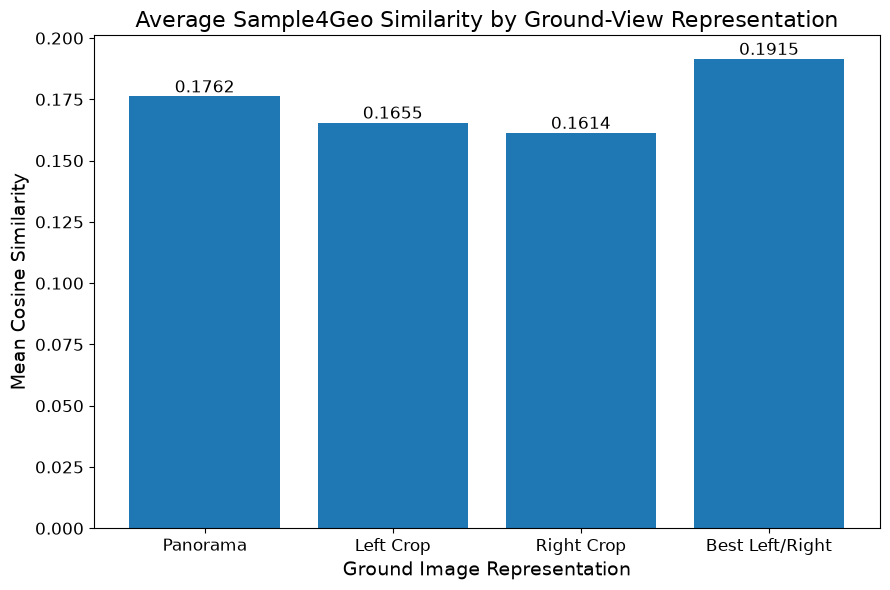

In [140]:
# Best crop for each image pair
df["best_crop_similarity"] = df[
    ["left_similarity", "right_similarity"]
].max(axis=1)

# Calculate average similarities
mean_scores = [
    df["panorama_similarity"].mean(),
    df["left_similarity"].mean(),
    df["right_similarity"].mean(),
    df["best_crop_similarity"].mean()
]

labels = [
    "Panorama",
    "Left Crop",
    "Right Crop",
    "Best Left/Right"
]

# Plot
plt.figure(figsize=(9, 6))

bars = plt.bar(
    labels,
    mean_scores
)

plt.ylabel(
    "Mean Cosine Similarity",
    fontsize=14
)

plt.xlabel(
    "Ground Image Representation",
    fontsize=14
)

plt.title(
    "Average Sample4Geo Similarity by Ground-View Representation",
    fontsize=16
)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

# Add exact values above bars
for bar, value in zip(bars, mean_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.4f}",
        ha="center",
        va="bottom",
        fontsize=12
    )

plt.tight_layout()
plt.show()

### Baseline Testing - one ground image and multiple sat image, get ranking and recall@

In [191]:
from pathlib import Path
import pandas as pd

ground_image_filename = "cat"

ground_path = Path(
    fr"E:\python_project\Geo\Test_ground_image\{ground_image_filename}.png"
)

satellite_folder = Path(
    r"E:\python_project\Geo\Test_sat_image"
)

# ---------------------------------------------------
# Ground embedding
# Calculate only ONCE
# ---------------------------------------------------

ground_embedding = get_embedding(
    ground_path,
    ground_transform
)


# ---------------------------------------------------
# Loop through all satellite candidates
# ---------------------------------------------------

results = []

satellite_files = sorted(
    satellite_folder.glob("*.png")
)

for satellite_path in satellite_files:

    # Satellite embedding
    satellite_embedding = get_embedding(
        satellite_path,
        sat_transform
    )

    # Cosine similarity
    similarity = (
        ground_embedding
        @ satellite_embedding.T
    ).item()

    results.append({
        "satellite_image": satellite_path.name,
        "cosine_similarity": similarity
    })


# ---------------------------------------------------
# Convert to DataFrame
# ---------------------------------------------------

df_rank = pd.DataFrame(results)


# ---------------------------------------------------
# Rank highest similarity first
# ---------------------------------------------------

df_rank = df_rank.sort_values(
    by="cosine_similarity",
    ascending=False
).reset_index(drop=True)

# Rank starts from 1
df_rank["rank"] = df_rank.index + 1

# Reorder columns
df_rank = df_rank[
    [
        "rank",
        "satellite_image",
        "cosine_similarity"
    ]
]


display(df_rank)

,rank,satellite_image,cosine_similarity
0,1,GABRIELLE_HAWKESBAY_SATELLITEV4.png,0.525838
1,2,GABRIELLE_HAWKESBAY_SATELLITEV3.png,0.485481
2,3,GABRIELLE_HAWKESBAY_SATELLITEV.png,0.419204
3,4,GABRIELLE_HAWKESBAY_SATELLITEV2.png,0.225471
4,5,104078525924854.png,0.099013


In [192]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt


def get_embedding_from_array(img_array, transform):
    tensor = transform(image=img_array)["image"]
    tensor = tensor.unsqueeze(0).to(device)

    with torch.inference_mode():
        embedding = model(tensor)
        embedding = F.normalize(embedding, p=2, dim=1)

    return embedding

In [193]:
ground_path = Path(
    fr"E:\python_project\Geo\Test_ground_image\{ground_image_filename}.png"
)

satellite_folder = Path(
    r"E:\python_project\Geo\Test_sat_image"
)

satellite_files = sorted(satellite_folder.glob("*.png"))

print("Satellite files found:")
for p in satellite_files:
    print(p.name)

Satellite files found:
104078525924854.png
GABRIELLE_HAWKESBAY_SATELLITEV.png
GABRIELLE_HAWKESBAY_SATELLITEV2.png
GABRIELLE_HAWKESBAY_SATELLITEV3.png
GABRIELLE_HAWKESBAY_SATELLITEV4.png


In [194]:
ground_embedding = get_embedding(
    ground_path,
    ground_transform
)

### For smooth heatmap version

In [195]:
from scipy.ndimage import gaussian_filter

def compute_similarity_heatmap_smooth(
    ground_embedding,
    satellite_path,
    window_size=160,
    stride=80,
    sigma=25
):
    sat_img = np.array(
        Image.open(satellite_path).convert("RGB")
    )

    h, w, _ = sat_img.shape

    win_h = min(window_size, h)
    win_w = min(window_size, w)

    # Sparse center-point similarity map
    score_map = np.zeros((h, w), dtype=np.float32)
    weight_map = np.zeros((h, w), dtype=np.float32)

    ys = list(range(0, max(h - win_h + 1, 1), stride))
    xs = list(range(0, max(w - win_w + 1, 1), stride))

    if ys[-1] != h - win_h:
        ys.append(h - win_h)

    if xs[-1] != w - win_w:
        xs.append(w - win_w)

    patch_scores = []

    for y in ys:
        for x in xs:
            patch = sat_img[y:y + win_h, x:x + win_w]

            patch_embedding = get_embedding_from_array(
                patch,
                sat_transform
            )

            sim = (
                ground_embedding @ patch_embedding.T
            ).item()

            cy = y + win_h // 2
            cx = x + win_w // 2

            score_map[cy, cx] += sim
            weight_map[cy, cx] += 1.0

            patch_scores.append({
                "x": x,
                "y": y,
                "center_x": cx,
                "center_y": cy,
                "similarity": sim
            })

    # Smooth both score and weight maps
    score_smooth = gaussian_filter(score_map, sigma=sigma)
    weight_smooth = gaussian_filter(weight_map, sigma=sigma)

    heatmap = score_smooth / np.maximum(weight_smooth, 1e-8)

    # Normalize for display only
    heatmap_norm = (
        heatmap - heatmap.min()
    ) / (
        heatmap.max() - heatmap.min() + 1e-8
    )

    # Find best hotspot
    max_y, max_x = np.unravel_index(
        np.argmax(heatmap),
        heatmap.shape
    )

    return sat_img, heatmap, heatmap_norm, pd.DataFrame(patch_scores), max_x, max_y

In [196]:
output_folder = Path(r"E:\python_project\Geo\pptimage")

summary_rows = []

for sat_path in satellite_files:

    sat_img, heatmap, heatmap_norm, patch_df, max_x, max_y = compute_similarity_heatmap_smooth(
        ground_embedding=ground_embedding,
        satellite_path=sat_path,
        window_size=160,
        stride=80,
        sigma=30
    )

    sat_embedding = get_embedding(
        sat_path,
        sat_transform
    )

    global_similarity = (
        ground_embedding @ sat_embedding.T
    ).item()

    fig, ax = plt.subplots(figsize=(12, 12))

    ax.imshow(sat_img)

    overlay = ax.imshow(
        heatmap_norm,
        cmap="turbo",
        alpha=0.25,
        interpolation="bicubic"
    )

    # Optional contour lines for hotspot feeling
    ax.contour(
        heatmap_norm,
        levels=8,
        colors="white",
        linewidths=0.7,
        alpha=0.55
    )

    # Black halo
    ax.scatter(
        max_x,
        max_y,
        marker="x",
        s=260,
        c="black",
        linewidths=6,
        alpha=0.75,
        zorder=5
    )

    # Bright lime green cross
    ax.scatter(
        max_x,
        max_y,
        marker="x",
        s=180,
        c="#7CFC00",   # bright lime green
        linewidths=3.5,
        zorder=6
    )

    ax.set_title(
        f"{sat_path.stem}\n"
        f"Global cosine = {global_similarity:.4f} | "
        f"Max hotspot similarity = {heatmap.max():.4f}",
        fontsize=16
    )

    ax.axis("off")

    cbar = fig.colorbar(
        overlay,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )
    cbar.set_label(
        "Normalized Local Similarity",
        fontsize=12
    )

    plt.tight_layout()

    out_path = output_folder / f"{sat_path.stem}_smooth_heatmap.png"

    fig.savefig(
        out_path,
        dpi=500,
        bbox_inches="tight"
    )

    plt.close(fig)

    print(f"Saved: {out_path}")

    summary_rows.append({
        "satellite_image": sat_path.name,
        "global_cosine_similarity": global_similarity,
        "max_hotspot_similarity": float(heatmap.max()),
        "saved_file": str(out_path)
    })

Saved: E:\python_project\Geo\pptimage\104078525924854_smooth_heatmap.png
Saved: E:\python_project\Geo\pptimage\GABRIELLE_HAWKESBAY_SATELLITEV_smooth_heatmap.png
Saved: E:\python_project\Geo\pptimage\GABRIELLE_HAWKESBAY_SATELLITEV2_smooth_heatmap.png
Saved: E:\python_project\Geo\pptimage\GABRIELLE_HAWKESBAY_SATELLITEV3_smooth_heatmap.png
Saved: E:\python_project\Geo\pptimage\GABRIELLE_HAWKESBAY_SATELLITEV4_smooth_heatmap.png


### Positive, easy negative, random negative and hard negative similarity distribution

In [197]:
def get_embedding(image_path, transform):

    img = np.array(
        Image.open(image_path).convert("RGB")
    )

    tensor = transform(
        image=img
    )["image"]

    tensor = tensor.unsqueeze(0).to(device)

    with torch.inference_mode():

        embedding = model(tensor)

        embedding = F.normalize(
            embedding,
            p=2,
            dim=1
        )

    return embedding

In [198]:
ground_folder = Path(
    r"E:\python_project\Geo\Test_ground_image"
)

In [199]:
query_groups = {

    "Positive": (
        ground_folder /
        "GABRIELLE_HAWKESBAY_CROSSV.png"
    ),

    "Easy Negative": (
        ground_folder /
        "Easy_negative.png"
    ),

    "Random Negative": (
        ground_folder /
        "random_negative.png"
    ),

    "Hard Negative": (
        ground_folder /
        "Hard_negative.jpg"
    )
}

In [200]:
satellite_folder = Path(
    r"E:\python_project\Geo\Test_sat_image"
)

In [201]:
satellite_files = []

for extension in ["*.png", "*.jpg", "*.jpeg"]:

    satellite_files.extend(
        satellite_folder.glob(extension)
    )

satellite_files = sorted(satellite_files)

print(
    "Number of satellite images:",
    len(satellite_files)
)

for path in satellite_files:
    print(path.name)

Number of satellite images: 8
104078525924854.png
GABRIELLE_HAWKESBAY_SATELLITEV.png
GABRIELLE_HAWKESBAY_SATELLITEV2.png
GABRIELLE_HAWKESBAY_SATELLITEV3.png
GABRIELLE_HAWKESBAY_SATELLITEV4.png
LongBay_SATELLITE.jpg
Okura_SATELLITE.jpg
RodneyWard_SATELLITE.jpg


In [202]:
satellite_embeddings = {}

for sat_path in satellite_files:

    satellite_embedding = get_embedding(
        sat_path,
        sat_transform
    )

    satellite_embeddings[
        sat_path.name
    ] = satellite_embedding

print(
    "Satellite embeddings completed:",
    len(satellite_embeddings)
)

Satellite embeddings completed: 8


In [203]:
results = []

for query_type, ground_path in query_groups.items():

    print(
        f"\nProcessing: {query_type}"
    )

    # Ground embedding calculated once
    ground_embedding = get_embedding(
        ground_path,
        ground_transform
    )

    # Compare with every satellite
    for sat_name, sat_embedding in satellite_embeddings.items():

        cosine_similarity = (
            ground_embedding
            @ sat_embedding.T
        ).item()

        results.append({

            "query_type": query_type,

            "ground_image":
                ground_path.name,

            "satellite_image":
                sat_name,

            "cosine_similarity":
                cosine_similarity

        })

        print(
            f"{sat_name:45s} "
            f"{cosine_similarity:.4f}"
        )


Processing: Positive
104078525924854.png                           0.0996
GABRIELLE_HAWKESBAY_SATELLITEV.png            0.4300
GABRIELLE_HAWKESBAY_SATELLITEV2.png           0.2240
GABRIELLE_HAWKESBAY_SATELLITEV3.png           0.4072
GABRIELLE_HAWKESBAY_SATELLITEV4.png           0.4078
LongBay_SATELLITE.jpg                         0.2158
Okura_SATELLITE.jpg                           0.1532
RodneyWard_SATELLITE.jpg                      0.2386

Processing: Easy Negative
104078525924854.png                           0.0990
GABRIELLE_HAWKESBAY_SATELLITEV.png            0.4192
GABRIELLE_HAWKESBAY_SATELLITEV2.png           0.2255
GABRIELLE_HAWKESBAY_SATELLITEV3.png           0.4855
GABRIELLE_HAWKESBAY_SATELLITEV4.png           0.5258
LongBay_SATELLITE.jpg                         0.2255
Okura_SATELLITE.jpg                           0.1023
RodneyWard_SATELLITE.jpg                      0.1683

Processing: Random Negative
104078525924854.png                           0.1127
GABRIELLE_HAWKESBAY_S

In [204]:
df_test = pd.DataFrame(
    results
)

display(df_test)

,query_type,ground_image,satellite_image,cosine_similarity
0,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,104078525924854.png,0.099634
1,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,GABRIELLE_HAWKESBAY_SATELLITEV.png,0.430045
2,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,GABRIELLE_HAWKESBAY_SATELLITEV2.png,0.223954
3,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,GABRIELLE_HAWKESBAY_SATELLITEV3.png,0.407210
4,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,GABRIELLE_HAWKESBAY_SATELLITEV4.png,0.407805
5,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,LongBay_SATELLITE.jpg,0.215769
6,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,Okura_SATELLITE.jpg,0.153189
7,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,RodneyWard_SATELLITE.jpg,0.238642
8,Easy Negative,Easy_negative.png,104078525924854.png,0.099013
9,Easy Negative,Easy_negative.png,GABRIELLE_HAWKESBAY_SATELLITEV.png,0.419204


In [205]:
df_ranked = (
    df_test
    .sort_values(
        [
            "query_type",
            "cosine_similarity"
        ],
        ascending=[
            True,
            False
        ]
    )
    .copy()
)

In [207]:
df_ranked["rank"] = (
    df_ranked
    .groupby("query_type")
    .cumcount()
    + 1
)

df_ranked = df_ranked[
    [
        "query_type",
        "rank",
        "ground_image",
        "satellite_image",
        "cosine_similarity"
    ]
]

display(df_ranked)

,query_type,rank,ground_image,satellite_image,cosine_similarity
12,Easy Negative,1,Easy_negative.png,GABRIELLE_HAWKESBAY_SATELLITEV4.png,0.525838
11,Easy Negative,2,Easy_negative.png,GABRIELLE_HAWKESBAY_SATELLITEV3.png,0.485481
9,Easy Negative,3,Easy_negative.png,GABRIELLE_HAWKESBAY_SATELLITEV.png,0.419204
10,Easy Negative,4,Easy_negative.png,GABRIELLE_HAWKESBAY_SATELLITEV2.png,0.225471
13,Easy Negative,5,Easy_negative.png,LongBay_SATELLITE.jpg,0.225451
15,Easy Negative,6,Easy_negative.png,RodneyWard_SATELLITE.jpg,0.168271
14,Easy Negative,7,Easy_negative.png,Okura_SATELLITE.jpg,0.102322
8,Easy Negative,8,Easy_negative.png,104078525924854.png,0.099013
27,Hard Negative,1,Hard_negative.jpg,GABRIELLE_HAWKESBAY_SATELLITEV3.png,0.339770
28,Hard Negative,2,Hard_negative.jpg,GABRIELLE_HAWKESBAY_SATELLITEV4.png,0.305010


### Summary statistics for each query type

In [208]:
summary = (
    df_test
    .groupby(
        "query_type"
    )["cosine_similarity"]
    .agg(
        [
            "count",
            "mean",
            "median",
            "std",
            "min",
            "max"
        ]
    )
    .round(4)
)

display(summary)

,count,mean,median,std,min,max
query_type,,,,,,
Easy Negative,8,0.2814,0.2255,0.1710,0.0990,0.5258
Hard Negative,8,0.1876,0.1397,0.0943,0.0994,0.3398
Positive,8,0.2720,0.2313,0.1266,0.0996,0.4300
Random Negative,8,0.2170,0.1750,0.1206,0.0847,0.4353


In [209]:
group_order = [
    "Positive",
    "Easy Negative",
    "Random Negative",
    "Hard Negative"
]

plot_data = [

    df_test.loc[
        df_test["query_type"] == group,
        "cosine_similarity"
    ].values

    for group in group_order
]

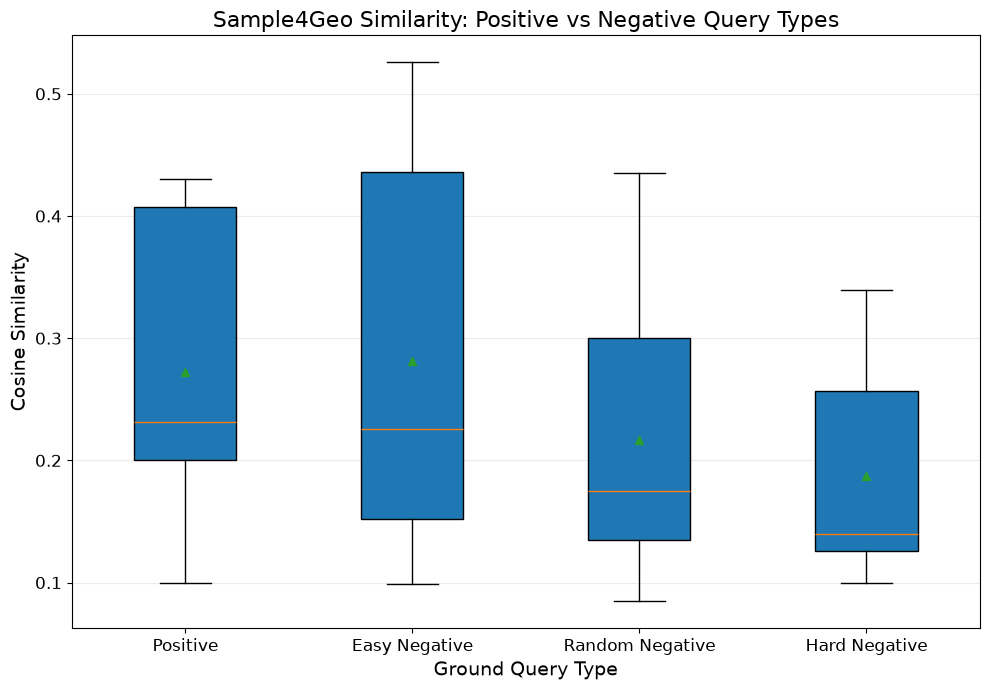

In [210]:
plt.figure(
    figsize=(10, 7)
)

plt.boxplot(
    plot_data,
    tick_labels=group_order,
    patch_artist=True,
    showmeans=True
)

plt.ylabel(
    "Cosine Similarity",
    fontsize=14
)

plt.xlabel(
    "Ground Query Type",
    fontsize=14
)

plt.title(
    "Sample4Geo Similarity: "
    "Positive vs Negative Query Types",
    fontsize=16
)

plt.xticks(
    fontsize=12
)

plt.yticks(
    fontsize=12
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.show()

### Similarity matrix for 4 set

In [211]:
heatmap_df = df_test.pivot(
    index="query_type",
    columns="satellite_image",
    values="cosine_similarity"
)

In [212]:
row_order = [
    "Positive",
    "Easy Negative",
    "Random Negative",
    "Hard Negative"
]

heatmap_df = heatmap_df.reindex(row_order)

In [213]:
display(heatmap_df)

satellite_image,104078525924854.png,GABRIELLE_HAWKESBAY_SATELLITEV.png,GABRIELLE_HAWKESBAY_SATELLITEV2.png,GABRIELLE_HAWKESBAY_SATELLITEV3.png,GABRIELLE_HAWKESBAY_SATELLITEV4.png,LongBay_SATELLITE.jpg,Okura_SATELLITE.jpg,RodneyWard_SATELLITE.jpg
query_type,,,,,,,,
Positive,0.099634,0.430045,0.223954,0.407210,0.407805,0.215769,0.153189,0.238642
Easy Negative,0.099013,0.419204,0.225471,0.485481,0.525838,0.225451,0.102322,0.168271
Random Negative,0.112717,0.315990,0.195845,0.435299,0.294560,0.154109,0.084668,0.142628
Hard Negative,0.102407,0.240577,0.144538,0.339770,0.305010,0.134942,0.099395,0.134141


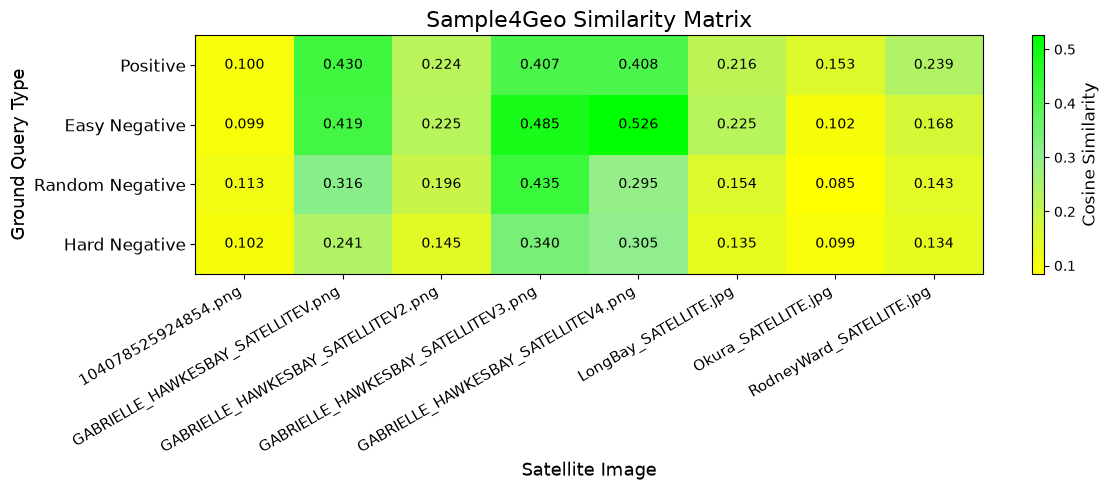

In [215]:
plt.figure(figsize=(12, 5))

from matplotlib.colors import LinearSegmentedColormap

custom_cmap = LinearSegmentedColormap.from_list(
    "yellow_green",
    ["yellow", "lightgreen", "lime"]
)

im = plt.imshow(
    heatmap_df.values,
    aspect="auto",
    cmap=custom_cmap   # yellow → orange → red
)

plt.xticks(
    ticks=range(len(heatmap_df.columns)),
    labels=heatmap_df.columns,
    rotation=30,
    ha="right",
    fontsize=11
)

plt.yticks(
    ticks=range(len(heatmap_df.index)),
    labels=heatmap_df.index,
    fontsize=12
)

plt.title(
    "Sample4Geo Similarity Matrix",
    fontsize=16
)

plt.xlabel(
    "Satellite Image",
    fontsize=13
)

plt.ylabel(
    "Ground Query Type",
    fontsize=13
)

cbar = plt.colorbar(im)
cbar.set_label(
    "Cosine Similarity",
    fontsize=12
)

# Put numeric values inside each cell
for i in range(heatmap_df.shape[0]):
    for j in range(heatmap_df.shape[1]):
        value = heatmap_df.values[i, j]
        plt.text(
            j,
            i,
            f"{value:.3f}",
            ha="center",
            va="center",
            fontsize=10,
            color="black"
        )

plt.tight_layout()
plt.show()